# Hidden Markov Models — A Complete Guide

**When the state you care about is hidden, but it leaves clues.** A Hidden Markov
Model (HMM) is a probabilistic model for sequences where an unobserved ("hidden")
state evolves as a Markov chain, and each state emits an observable signal. You see
the signals; you must infer the states.

This notebook builds HMMs from the ground up — the probability theory, the three
classical inference problems and **the algorithms that solve them implemented from
scratch in NumPy**, the EM learning procedure, the continuous (Gaussian) extension,
and real applications — all with runnable code and rich visuals.

---

## Table of contents

1. **Intuition** — the hidden-state idea
2. **Formal definition** — states, transitions $A$, emissions $B$, prior $\pi$
3. **The generative process** — sampling from an HMM
4. **The three canonical problems** (Rabiner, 1989)
5. **Problem 1 — Evaluation:** the *Forward* (and Backward) algorithm
6. **Problem 2 — Decoding:** the *Viterbi* algorithm
7. **Posterior decoding** — forward–backward & smoothing
8. **Problem 3 — Learning:** *Baum–Welch* (EM) from scratch
9. **Continuous emissions** — the Gaussian HMM
10. **Application — financial regime detection** (bull/bear markets)
11. **Numerical stability, pitfalls & cheat sheet**

In [1]:
# --- Setup -------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle
from matplotlib.collections import LineCollection
import scipy.stats as st

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
rng = np.random.default_rng(7)
np.set_printoptions(precision=4, suppress=True)
print("NumPy", np.__version__)

# --- explanation helper: renders formatted text as output under a visual ---
from IPython.display import display, HTML
def explain(html):
    display(HTML('<div style="background:#f6f8fa;border-left:4px solid #2563eb;padding:10px 14px;margin-top:6px;border-radius:6px;font-size:14px;line-height:1.55;color:#1f2937">' + html + '</div>'))

NumPy 2.3.5


## 1. Intuition

Imagine you live in a windowless basement and want to know the **weather** (Hot or
Cold) each day. You can't see it — but you *can* see how many **ice creams** your
roommate eats (1, 2, or 3). Hot days make ice cream more likely. The weather is the
**hidden state**; the ice-cream count is the **observation**.

Two assumptions define the model:

1. **Markov property (hidden chain):** tomorrow's weather depends only on today's, not
   the full history. $\;P(s_{t+1}\mid s_t, s_{t-1},\dots) = P(s_{t+1}\mid s_t).$
2. **Output independence:** today's observation depends only on today's hidden state.
   $\;P(o_t \mid s_t, \text{everything else}) = P(o_t\mid s_t).$

```
   hidden:   s_1  ->  s_2  ->  s_3  ->  ...   (Markov chain you cannot see)
              |        |        |
              v        v        v
   observed:  o_1      o_2      o_3      ...   (the clues you do see)
```

HMMs power speech recognition, part-of-speech tagging, gene finding, gesture
recognition, and financial regime detection — anywhere a sequence of observations is
driven by hidden modes.

## 2. Formal definition

An HMM with $N$ hidden states and $M$ discrete observation symbols is the triple
$\lambda = (A, B, \pi)$:

| Symbol | Name | Shape | Meaning |
|---|---|---|---|
| $\pi$ | initial distribution | $(N,)$ | $\pi_i = P(s_1 = i)$ |
| $A$ | transition matrix | $(N,N)$ | $A_{ij} = P(s_{t+1}=j \mid s_t = i)$ |
| $B$ | emission matrix | $(N,M)$ | $B_{j}(k) = P(o_t = v_k \mid s_t = j)$ |

Each row of $A$ and $B$, and $\pi$ itself, is a probability distribution that **sums to
1**. The **joint probability** of a hidden path $s_{1:T}$ and observations $o_{1:T}$
factorizes neatly thanks to the two assumptions:

$$P(s_{1:T}, o_{1:T}\mid\lambda) \;=\; \underbrace{\pi_{s_1}}_{\text{start}}\;
\underbrace{B_{s_1}(o_1)}_{\text{emit}}\;
\prod_{t=2}^{T} \underbrace{A_{s_{t-1}s_t}}_{\text{transition}}\;
\underbrace{B_{s_t}(o_t)}_{\text{emit}}.$$

Let's instantiate the ice-cream model.

In [2]:
states = ["Hot", "Cold"]
obs_symbols = [1, 2, 3]          # ice creams eaten
N, M = len(states), len(obs_symbols)

pi = np.array([0.6, 0.4])                 # P(start Hot), P(start Cold)
A = np.array([[0.7, 0.3],                 # Hot -> Hot, Hot -> Cold
              [0.4, 0.6]])                # Cold-> Hot, Cold-> Cold
B = np.array([[0.2, 0.4, 0.4],            # Hot emits 1,2,3 ice creams
              [0.5, 0.4, 0.1]])           # Cold emits 1,2,3 ice creams

assert np.allclose(pi.sum(), 1) and np.allclose(A.sum(1), 1) and np.allclose(B.sum(1), 1)
print("pi =", pi)
print("A  =\n", A)
print("B  =\n", B)

pi = [0.6 0.4]
A  =
 [[0.7 0.3]
 [0.4 0.6]]
B  =
 [[0.2 0.4 0.4]
 [0.5 0.4 0.1]]


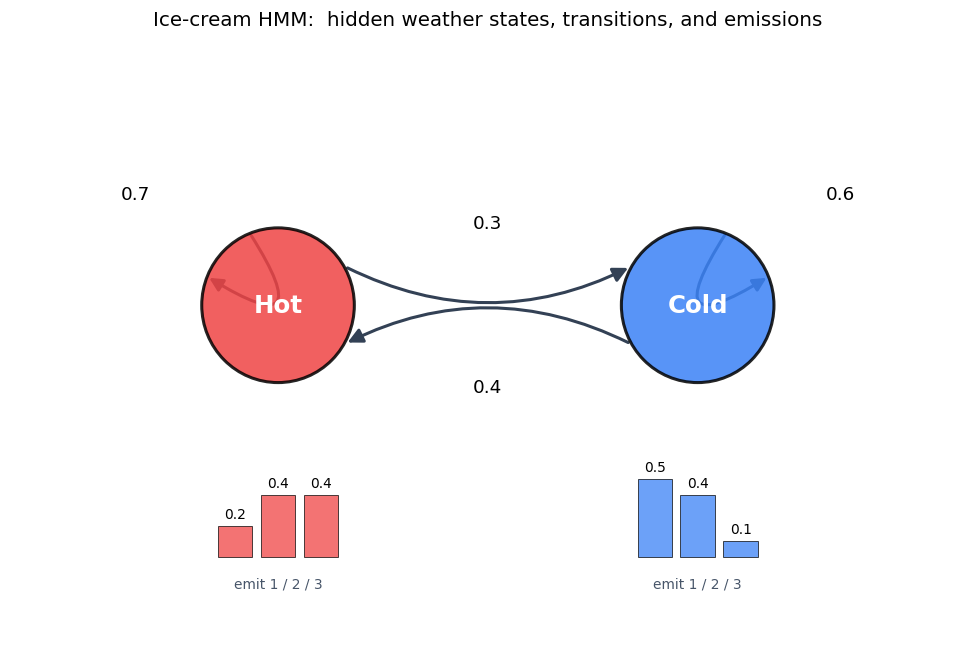

In [3]:
# Visualize the model as a state-transition diagram (drawn manually = no extra deps).
fig, ax = plt.subplots(figsize=(9, 6))
pos = {0: np.array([-2.2, 0]), 1: np.array([2.2, 0])}     # Hot left, Cold right
colors = ["#ef4444", "#3b82f6"]

def curved_arrow(ax, p0, p1, rad, label, color="#334155"):
    arr = FancyArrowPatch(p0, p1, connectionstyle=f"arc3,rad={rad}",
                          arrowstyle="-|>", mutation_scale=20, lw=2, color=color)
    ax.add_patch(arr)
    mid = (p0 + p1)/2 + np.array([-(p1-p0)[1], (p1-p0)[0]])*rad*0.6
    ax.text(*mid, label, fontsize=12, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9))

# state circles
for i, p in pos.items():
    ax.add_patch(Circle(p, 0.8, fc=colors[i], ec="black", lw=2, alpha=0.85, zorder=3))
    ax.text(*p, states[i], fontsize=16, color="white", ha="center", va="center",
            weight="bold", zorder=4)
# transitions between states
curved_arrow(ax, pos[0]+[0.7,0.4],  pos[1]+[-0.7,0.4],  0.25, f"{A[0,1]:.1f}")
curved_arrow(ax, pos[1]+[-0.7,-0.4],pos[0]+[0.7,-0.4],  0.25, f"{A[1,0]:.1f}")
# self loops
for i, p in pos.items():
    sgn = -1 if i == 0 else 1
    arr = FancyArrowPatch(p+[sgn*0.3,0.75], p+[sgn*0.75,0.3],
                          connectionstyle=f"arc3,rad={sgn*2.2}",
                          arrowstyle="-|>", mutation_scale=18, lw=2, color="#334155")
    ax.add_patch(arr)
    ax.text(*(p+[sgn*1.5,1.1]), f"{A[i,i]:.1f}", fontsize=12, ha="center")
# emission bars under each state (drawn on a baseline well below the circles)
base = -2.6; scale = 1.6; off = np.array([-0.45, 0.0, 0.45])
for i, p in pos.items():
    bx = p[0]
    ax.bar(bx + off, B[i]*scale, width=0.36, bottom=base, color=colors[i],
           alpha=0.75, edgecolor="black", lw=0.6, zorder=3)
    for k, v in enumerate(B[i]):
        ax.text(bx + off[k], base + v*scale + 0.08, f"{v:.1f}", ha="center", fontsize=9)
    ax.text(bx, base - 0.32, "emit 1 / 2 / 3", ha="center", fontsize=9, color="#475569")

ax.set(xlim=(-5, 5), ylim=(-3.4, 2.8)); ax.axis("off")
ax.set_title("Ice-cream HMM:  hidden weather states, transitions, and emissions", fontsize=13)
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> The two circles are the <b>hidden states</b> (Hot / Cold). Straight arrows are <b>transition</b> probabilities A (Hot&rarr;Cold = 0.3); curved self-loops are the chance of staying (Hot&rarr;Hot = 0.7). The bars beneath each state are its <b>emission</b> probabilities B &mdash; how likely 1/2/3 ice creams are in that weather.<br><b>Takeaway:</b> an HMM is fully described by three pieces &mdash; start &pi;, transitions A, emissions B.
''')

## 3. The generative process — sampling from an HMM

An HMM is a *generative* model: it describes a recipe for producing data. To draw a
sequence of length $T$:

1. Sample the first state $s_1 \sim \pi$.
2. Emit $o_1 \sim B_{s_1}(\cdot)$.
3. For $t = 2,\dots,T$: transition $s_t \sim A_{s_{t-1}}(\cdot)$, then emit
   $o_t \sim B_{s_t}(\cdot)$.

We'll sample a sequence and keep the (normally hidden) true states so we can later
check whether our decoding algorithms recover them.

First 15 hidden states : ['Cold', 'Cold', 'Hot', 'Hot', 'Cold', 'Hot', 'Hot', 'Hot', 'Cold', 'Cold', 'Hot', 'Hot', 'Hot', 'Hot', 'Hot']
First 15 observations  : [2, 1, 3, 3, 1, 2, 2, 2, 2, 3, 1, 1, 2, 3, 2]


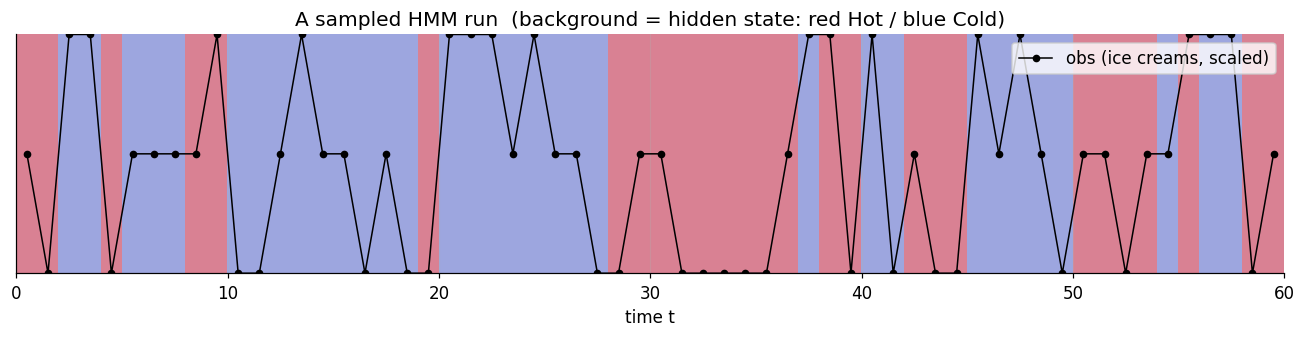

In [4]:
def sample_hmm(pi, A, B, T, rng):
    N = len(pi)
    states_seq = np.empty(T, dtype=int)
    obs_seq    = np.empty(T, dtype=int)
    states_seq[0] = rng.choice(N, p=pi)
    obs_seq[0]    = rng.choice(B.shape[1], p=B[states_seq[0]])
    for t in range(1, T):
        states_seq[t] = rng.choice(N, p=A[states_seq[t-1]])
        obs_seq[t]    = rng.choice(B.shape[1], p=B[states_seq[t]])
    return states_seq, obs_seq

T = 60
true_states, obs = sample_hmm(pi, A, B, T, rng)
print("First 15 hidden states :", [states[s] for s in true_states[:15]])
print("First 15 observations  :", (obs[:15] + 1).tolist())   # +1 -> ice-cream counts

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.imshow(true_states.reshape(1, -1), aspect="auto", cmap="coolwarm",
          extent=[0, T, 0, 1], alpha=0.5)
ax.plot(np.arange(T)+0.5, obs/2 , "ko-", ms=4, lw=1, label="obs (ice creams, scaled)")
ax.set(yticks=[], xlabel="time t", title="A sampled HMM run  (background = hidden state: red Hot / blue Cold)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> The colored background is the (normally hidden) true weather over 60 days &mdash; red Hot, blue Cold. The black dots are what you actually observe: the ice-cream counts.<br><b>Takeaway:</b> the states are &lsquo;sticky&rsquo; (long single-color runs) and observations only hint at the state. Resolving that ambiguity is the job of the algorithms below.
''')

## 4. The three canonical problems

Rabiner's classic 1989 tutorial frames everything an HMM is used for as **three
problems**:

| # | Problem | Question | Algorithm |
|---|---|---|---|
| **1. Evaluation** | likelihood | Given $\lambda$ and $o_{1:T}$, what is $P(o_{1:T}\mid\lambda)$? | **Forward** |
| **2. Decoding** | best path | Given $\lambda$ and $o_{1:T}$, what is the most likely hidden path $s_{1:T}^\star$? | **Viterbi** |
| **3. Learning** | fit | Given only $o_{1:T}$, find $\lambda$ that maximizes $P(o_{1:T}\mid\lambda)$ | **Baum–Welch (EM)** |

A naive solution to Problem 1 — summing over **all** $N^T$ possible hidden paths — is
astronomically expensive ($2^{60}\approx 10^{18}$ here). Dynamic programming reduces
this to $\mathcal{O}(N^2 T)$. That reduction is the whole game.

## 5. Problem 1 — Evaluation: the Forward algorithm

Define the **forward variable** — the joint probability of seeing the observations up
to time $t$ *and* being in state $i$ at time $t$:

$$\alpha_t(i) \;=\; P(o_1, o_2, \dots, o_t,\; s_t = i \mid \lambda).$$

It obeys a recursion (sum over where you came from, then emit):

$$\alpha_1(i) = \pi_i B_i(o_1),\qquad
\alpha_{t}(j) = \Big[\textstyle\sum_{i=1}^N \alpha_{t-1}(i)\,A_{ij}\Big]\,B_j(o_t).$$

The total likelihood is the sum over all final states:

$$P(o_{1:T}\mid\lambda) = \sum_{i=1}^N \alpha_T(i).$$

### Numerical underflow & scaling
Multiplying $T$ probabilities $<1$ drives $\alpha$ toward zero exponentially. We fix
this by **rescaling** $\alpha_t$ to sum to 1 each step, storing the scaling factors
$c_t$. The log-likelihood is then the stable sum $\;\log P = -\sum_t \log c_t$.

In [5]:
def forward(obs, pi, A, B):
    '''Scaled forward algorithm. Returns (alpha_hat, c, loglik).'''
    T, N = len(obs), len(pi)
    alpha = np.zeros((T, N))
    c = np.zeros(T)                       # scaling factors
    alpha[0] = pi * B[:, obs[0]]
    c[0] = alpha[0].sum()
    alpha[0] /= c[0]
    for t in range(1, T):
        alpha[t] = (alpha[t-1] @ A) * B[:, obs[t]]
        c[t] = alpha[t].sum()
        alpha[t] /= c[t]
    loglik = np.log(c).sum()              # log P(o | lambda)
    return alpha, c, loglik

alpha, c, loglik = forward(obs, pi, A, B)
print(f"log P(observations | model) = {loglik:.4f}")
print(f"P(observations | model)     = {np.exp(loglik):.3e}   (tiny, hence log-space)")

# Brute-force check on a SHORT sequence (sum over all N^t paths)
import itertools
short = obs[:8]
total = 0.0
for path in itertools.product(range(N), repeat=len(short)):
    p = pi[path[0]] * B[path[0], short[0]]
    for t in range(1, len(short)):
        p *= A[path[t-1], path[t]] * B[path[t], short[t]]
    total += p
_, _, ll_short = forward(short, pi, A, B)
print(f"\nBrute force (8 steps, {N**8} paths): {total:.6e}")
print(f"Forward algorithm           : {np.exp(ll_short):.6e}   <- identical")

log P(observations | model) = -65.0379
P(observations | model)     = 5.680e-29   (tiny, hence log-space)

Brute force (8 steps, 256 paths): 1.851326e-04
Forward algorithm           : 1.851326e-04   <- identical


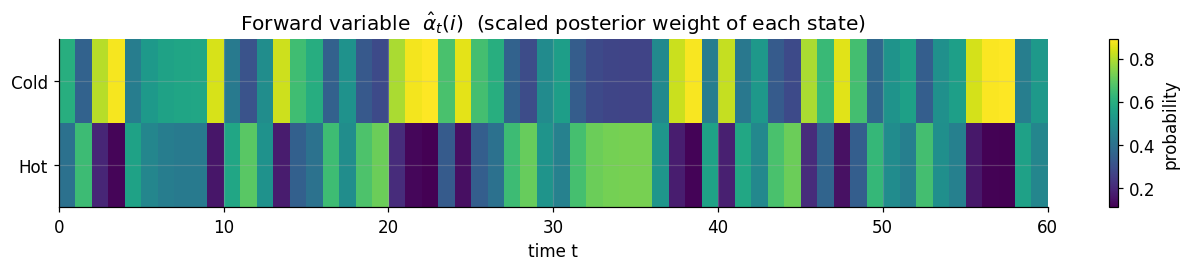

In [6]:
# Visualize the forward variable as a heatmap over time.
fig, ax = plt.subplots(figsize=(12, 2.6))
im = ax.imshow(alpha.T, aspect="auto", cmap="viridis", extent=[0, T, -0.5, N-0.5])
ax.set(yticks=range(N), yticklabels=states, xlabel="time t",
       title=r"Forward variable  $\hat\alpha_t(i)$  (scaled posterior weight of each state)")
plt.colorbar(im, ax=ax, label="probability"); plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> Each column is a time step; brightness is the (scaled) forward weight &mdash; the model&rsquo;s running belief in each state given the observations so far.<br><b>Takeaway:</b> summing the final column gives the total likelihood P(obs) &mdash; the answer to <b>Problem&nbsp;1</b>, in linear time instead of summing over 2<sup>60</sup> paths.
''')

### The Backward algorithm (the mirror image)

Symmetrically, the **backward variable** is the probability of the *future*
observations given the current state:

$$\beta_t(i) = P(o_{t+1}, \dots, o_T \mid s_t = i, \lambda),\qquad
\beta_T(i)=1,\quad
\beta_t(i) = \sum_{j=1}^N A_{ij}\,B_j(o_{t+1})\,\beta_{t+1}(j).$$

Together $\alpha$ and $\beta$ give the **smoothed posterior** $\gamma_t(i)=P(s_t=i\mid
o_{1:T})$ used in decoding and learning. We reuse the forward scaling factors $c_t$ to
keep $\beta$ stable.

In [7]:
def backward(obs, A, B, c):
    '''Scaled backward algorithm using forward's scaling factors c.'''
    T, N = len(obs), A.shape[0]
    beta = np.zeros((T, N))
    beta[-1] = 1.0 / c[-1]
    for t in range(T-2, -1, -1):
        beta[t] = (A @ (B[:, obs[t+1]] * beta[t+1])) / c[t]
    return beta

beta = backward(obs, A, B, c)
# Smoothed posterior gamma_t(i) = P(s_t = i | all observations)
gamma = alpha * beta
gamma /= gamma.sum(axis=1, keepdims=True)
print("Posterior P(state | all obs) at t=0:", dict(zip(states, gamma[0].round(3))))

Posterior P(state | all obs) at t=0: {'Hot': np.float64(0.561), 'Cold': np.float64(0.439)}


## 6. Problem 2 — Decoding: the Viterbi algorithm

The Forward algorithm *sums* over paths. To find the single **most likely hidden
path**, we instead *maximize* — replace $\sum$ with $\max$. Define

$$\delta_t(i) = \max_{s_1,\dots,s_{t-1}} P(s_1,\dots,s_{t-1}, s_t=i,\; o_{1:t}\mid\lambda),$$

the probability of the best path ending in state $i$ at time $t$. Recursion:

$$\delta_1(i)=\pi_i B_i(o_1),\qquad
\delta_t(j) = \max_i\big[\delta_{t-1}(i)A_{ij}\big]\,B_j(o_t),$$

while **back-pointers** $\psi_t(j)=\arg\max_i[\delta_{t-1}(i)A_{ij}]$ remember the
winning predecessor. We then **backtrack** from $\arg\max_i \delta_T(i)$ to recover the
optimal sequence $s^\star_{1:T}$.

We work in **log-space** ($\log\delta$), turning products into sums — exact and
underflow-proof.

Viterbi path log-probability : -85.284
Decoding accuracy vs truth   : 63.3%


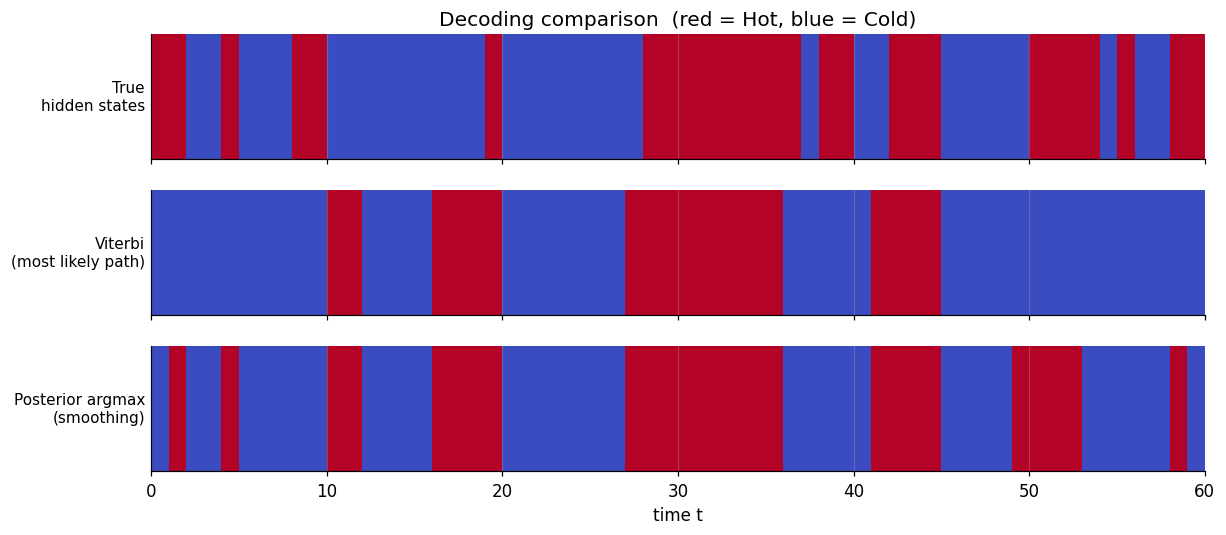

In [8]:
def viterbi(obs, pi, A, B):
    T, N = len(obs), len(pi)
    logA, logB, logpi = np.log(A + 1e-300), np.log(B + 1e-300), np.log(pi + 1e-300)
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)
    delta[0] = logpi + logB[:, obs[0]]
    for t in range(1, T):
        scores = delta[t-1][:, None] + logA          # (N_from, N_to)
        psi[t] = scores.argmax(axis=0)
        delta[t] = scores.max(axis=0) + logB[:, obs[t]]
    # backtrack
    path = np.zeros(T, dtype=int)
    path[-1] = delta[-1].argmax()
    for t in range(T-2, -1, -1):
        path[t] = psi[t+1, path[t+1]]
    return path, delta[-1].max()      # path, log-prob of that path

vit_path, vit_logp = viterbi(obs, pi, A, B)
accuracy = (vit_path == true_states).mean()
print(f"Viterbi path log-probability : {vit_logp:.3f}")
print(f"Decoding accuracy vs truth   : {accuracy:.1%}")

# Compare true / Viterbi / posterior-argmax decodings
post_path = gamma.argmax(axis=1)
fig, axes = plt.subplots(3, 1, figsize=(12, 5), sharex=True)
panel_labels = ["True\nhidden states", "Viterbi\n(most likely path)",
                "Posterior argmax\n(smoothing)"]
for ax, seq, name in zip(axes, [true_states, vit_path, post_path], panel_labels):
    ax.imshow(seq.reshape(1, -1), aspect="auto", cmap="coolwarm", extent=[0, T, 0, 1])
    ax.set_yticks([]); ax.set_ylim(0, 1)
    # horizontal labels placed to the LEFT so they never overlap the thin bands
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=10)
axes[-1].set_xlabel("time t")
axes[0].set_title("Decoding comparison  (red = Hot, blue = Cold)")
plt.tight_layout(); plt.subplots_adjust(left=0.18, hspace=0.25); plt.show()

explain(r'''
<b>How to read this.</b> Three timelines: the <b>true</b> hidden states, the <b>Viterbi</b> most-likely path, and the <b>posterior-argmax</b> decoding. Where they agree the model is confident; where they differ the observations were ambiguous.<br><b>Takeaway:</b> Viterbi returns a single globally-consistent path (<b>Problem&nbsp;2</b>). Accuracy is modest on this toy because Hot and Cold emit similar counts.
''')

### Viterbi as a trellis (lattice) shortest path

Decoding is really a **shortest-path** problem on a trellis: $N$ nodes per time step,
edges weighted by $-\log(A_{ij}B_j(o_t))$. Viterbi is dynamic programming over this
lattice. Below, the highlighted route is the recovered optimal path.

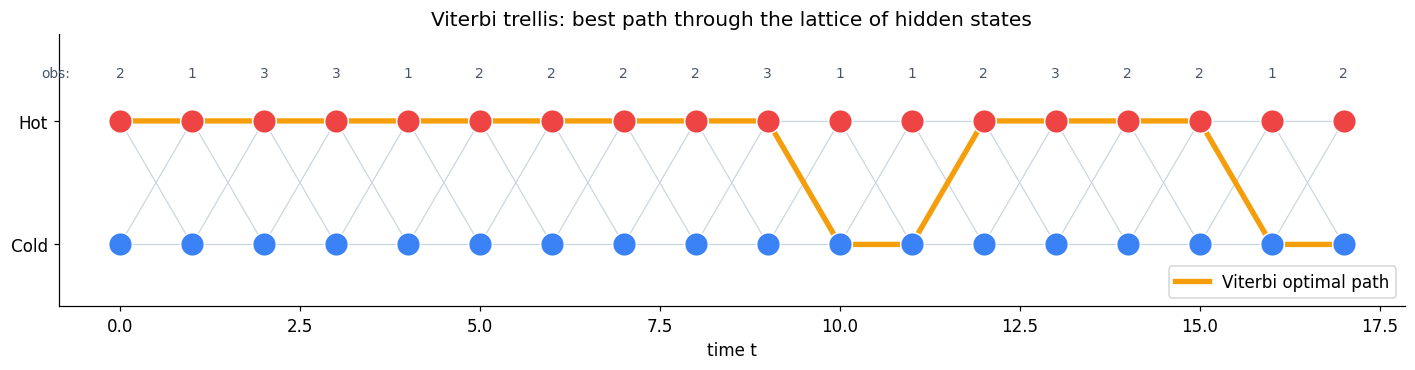

In [9]:
fig, ax = plt.subplots(figsize=(13, 3.5))
Tshow = 18
ys = {0: 1, 1: 0}
# faint full lattice
for t in range(Tshow-1):
    for i in range(N):
        for j in range(N):
            ax.plot([t, t+1], [ys[i], ys[j]], color="#cbd5e1", lw=0.8, zorder=1)
# all nodes
for t in range(Tshow):
    for i in range(N):
        ax.scatter(t, ys[i], s=240, color="#ef4444" if i==0 else "#3b82f6",
                   zorder=3, edgecolor="white")
# winning Viterbi path
px = np.arange(Tshow)
py = [ys[s] for s in vit_path[:Tshow]]
ax.plot(px, py, color="#f59e0b", lw=3.5, zorder=2, label="Viterbi optimal path")
# observations annotated
for t in range(Tshow):
    ax.text(t, 1.35, str(obs[t]+1), ha="center", fontsize=9, color="#475569")
ax.text(-1.1, 1.35, "obs:", fontsize=9, color="#475569")
ax.set(yticks=[0,1], yticklabels=["Cold","Hot"], xlabel="time t", ylim=(-0.5, 1.7),
       title="Viterbi trellis: best path through the lattice of hidden states")
ax.legend(loc="lower right"); ax.grid(False)
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> Every time step has one node per state; faint grey lines are all possible transitions. The gold path is the single highest-probability route Viterbi picks, given the observations printed on top.<br><b>Takeaway:</b> decoding is a shortest-path problem through this lattice &mdash; dynamic programming finds the best path without enumerating them all.
''')

## 7. Posterior decoding vs Viterbi — what's the difference?

- **Viterbi** maximizes the probability of the **whole path** jointly. It guarantees a
  *valid, self-consistent* sequence (one allowed by the transition matrix).
- **Posterior (forward–backward) decoding** picks, at each $t$ independently, the state
  with highest marginal $\gamma_t(i)$. It maximizes the **per-timestep** accuracy but
  the stitched-together sequence can be globally inconsistent (even contain forbidden
  transitions).

Use Viterbi when you need a coherent path (speech, alignment); use posterior marginals
when you want per-position confidence. The $\gamma$ posteriors below show the model's
*uncertainty* — wherever the band is near 0.5 the state is genuinely ambiguous.

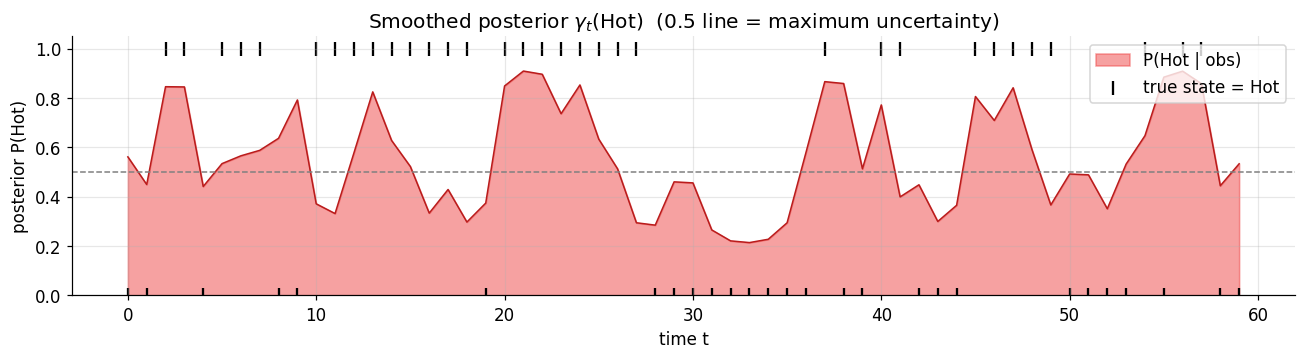

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.fill_between(range(T), gamma[:, 0], color="#ef4444", alpha=0.5, label="P(Hot | obs)")
ax.plot(range(T), gamma[:, 0], color="#b91c1c", lw=1)
ax.scatter(range(T), (true_states==0)*1.0, marker="|",
           color="black", s=80, label="true state = Hot")
ax.axhline(0.5, color="gray", ls="--", lw=1)
ax.set(ylim=(0,1.05), xlabel="time t", ylabel="posterior P(Hot)",
       title=r"Smoothed posterior $\gamma_t(\mathrm{Hot})$  (0.5 line = maximum uncertainty)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> The red curve is the smoothed probability of Hot each day (using all observations). Near 1 or 0 the model is certain; near the dashed 0.5 line it is undecided. Black ticks mark the true Hot days.<br><b>Takeaway:</b> this gives per-day confidence &mdash; more informative than a hard label, and exactly what Baum&ndash;Welch uses to re-estimate the model.
''')

## 8. Problem 3 — Learning: the Baum–Welch algorithm (EM)

The hardest problem: given **only** observations, estimate $\lambda=(A,B,\pi)$. There's
no closed form, so we use **Expectation–Maximization**. Baum–Welch is EM specialized to
HMMs and is guaranteed to **never decrease** the likelihood each iteration (it climbs to
a *local* optimum).

**E-step** — using current $\lambda$, run forward–backward to get the responsibilities:

$$\gamma_t(i) = P(s_t=i\mid o_{1:T},\lambda) = \frac{\alpha_t(i)\beta_t(i)}{\sum_k \alpha_t(k)\beta_t(k)},$$

$$\xi_t(i,j) = P(s_t=i, s_{t+1}=j\mid o_{1:T},\lambda) \propto
\alpha_t(i)\,A_{ij}\,B_j(o_{t+1})\,\beta_{t+1}(j).$$

**M-step** — re-estimate parameters as expected counts (intuitive frequency ratios):

$$\hat\pi_i = \gamma_1(i),\qquad
\hat A_{ij} = \frac{\sum_{t=1}^{T-1}\xi_t(i,j)}{\sum_{t=1}^{T-1}\gamma_t(i)},\qquad
\hat B_j(k) = \frac{\sum_{t:\,o_t=v_k}\gamma_t(j)}{\sum_{t=1}^{T}\gamma_t(j)}.$$

Iterate E and M until the log-likelihood plateaus. Let's **learn the model from data
alone**, starting from random parameters, and watch it recover the truth.

In [11]:
def baum_welch(obs, N, M, n_iter=60, seed=0):
    r = np.random.default_rng(seed)
    # random but valid initial parameters
    pi_h = r.dirichlet(np.ones(N))
    A_h = r.dirichlet(np.ones(N), size=N)
    B_h = r.dirichlet(np.ones(M), size=N)
    T = len(obs)
    history = []
    for _ in range(n_iter):
        # ---- E-step: scaled forward-backward ----
        a, c, ll = forward(obs, pi_h, A_h, B_h)
        b = backward(obs, A_h, B_h, c)
        history.append(ll)
        g = a * b
        g /= g.sum(axis=1, keepdims=True)                  # gamma_t(i)
        # xi_t(i,j), normalized per t
        xi = np.zeros((T-1, N, N))
        for t in range(T-1):
            xi[t] = a[t][:, None] * A_h * B_h[:, obs[t+1]][None, :] * b[t+1][None, :]
            xi[t] /= xi[t].sum()
        # ---- M-step ----
        pi_h = g[0]
        A_h = xi.sum(axis=0) / g[:-1].sum(axis=0)[:, None]
        for k in range(M):
            B_h[:, k] = g[obs == k].sum(axis=0)
        B_h /= g.sum(axis=0)[:, None]
    return pi_h, A_h, B_h, history

# Learn from a long sequence sampled from the TRUE model
true_states_long, obs_long = sample_hmm(pi, A, B, 3000, rng)
pi_l, A_l, B_l, hist = baum_welch(obs_long, N, M, n_iter=80, seed=3)

print("Log-likelihood:  start = %.2f   ->   end = %.2f  (monotonically increasing)"
      % (hist[0], hist[-1]))
print("\nLearned A (rows may be label-swapped vs truth):\n", A_l)
print("\nTrue A:\n", A)

Log-likelihood:  start = -5028.51   ->   end = -3250.48  (monotonically increasing)

Learned A (rows may be label-swapped vs truth):
 [[0.6175 0.3825]
 [0.4672 0.5328]]

True A:
 [[0.7 0.3]
 [0.4 0.6]]


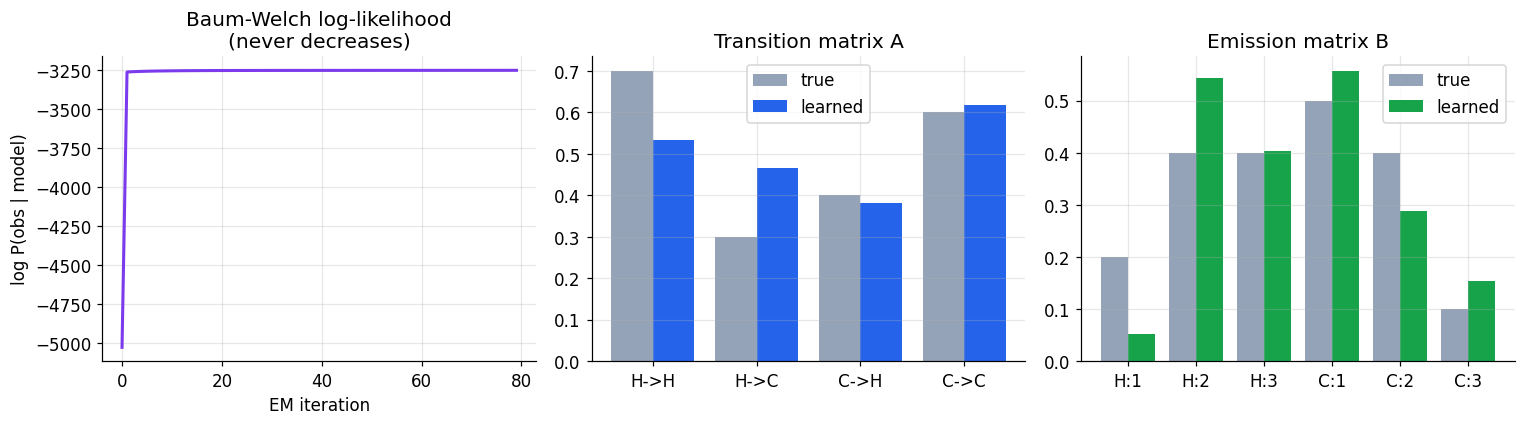

Baum-Welch recovered the true parameters from observations alone (up to label order).


In [12]:
# Note: EM can learn the two states in swapped order. Align by matching emissions to truth.
def align(B_learned, A_learned, pi_learned, B_true):
    # match each learned state to the true state with closest emission row
    perm = []
    for j in range(B_true.shape[0]):
        perm.append(np.argmin(np.abs(B_learned - B_true[j]).sum(axis=1)))
    perm = np.array(perm)
    return (pi_learned[perm], A_learned[np.ix_(perm, perm)], B_learned[perm])

pi_a, A_a, B_a = align(B_l, A_l, pi_l, B)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
# convergence curve
axes[0].plot(hist, color="#7c3aed", lw=2)
axes[0].set(title="Baum-Welch log-likelihood\n(never decreases)", xlabel="EM iteration",
            ylabel="log P(obs | model)")
# learned vs true A
x = np.arange(4)
axes[1].bar(x-0.2, A.ravel(), 0.4, label="true", color="#94a3b8")
axes[1].bar(x+0.2, A_a.ravel(), 0.4, label="learned", color="#2563eb")
axes[1].set(title="Transition matrix A", xticks=x,
            xticklabels=["H->H","H->C","C->H","C->C"]); axes[1].legend()
# learned vs true B
x = np.arange(6)
axes[2].bar(x-0.2, B.ravel(), 0.4, label="true", color="#94a3b8")
axes[2].bar(x+0.2, B_a.ravel(), 0.4, label="learned", color="#16a34a")
axes[2].set(title="Emission matrix B", xticks=x,
            xticklabels=["H:1","H:2","H:3","C:1","C:2","C:3"]); axes[2].legend()
plt.tight_layout(); plt.show()
print("Baum-Welch recovered the true parameters from observations alone (up to label order).")

explain(r'''
<b>How to read this.</b> <i>Left:</i> the log-likelihood rises at every EM iteration and plateaus &mdash; Baum&ndash;Welch never decreases it. <i>Middle/Right:</i> the learned transition A and emission B bars sit almost on top of the true values.<br><b>Takeaway:</b> from random parameters and only observations, EM recovered the generating model (<b>Problem&nbsp;3</b>). Label order can swap between runs, so we align by emissions first.
''')

## 9. Continuous emissions — the Gaussian HMM

So far observations were discrete symbols. In most real applications (stock returns,
audio features, sensor readings) observations are **continuous**. We swap the emission
*matrix* $B$ for a **probability density** per state — most commonly Gaussian:

$$b_j(o) = \mathcal{N}(o \mid \mu_j, \sigma_j^2)
= \frac{1}{\sqrt{2\pi\sigma_j^2}}\exp\!\left(-\frac{(o-\mu_j)^2}{2\sigma_j^2}\right).$$

The forward/backward/Viterbi recursions are **identical** — just replace $B_j(o_t)$
with $b_j(o_t)$. The Baum–Welch M-step for the emission parameters becomes the familiar
**responsibility-weighted mean and variance**:

$$\hat\mu_j = \frac{\sum_t \gamma_t(j)\,o_t}{\sum_t \gamma_t(j)},\qquad
\hat\sigma_j^2 = \frac{\sum_t \gamma_t(j)\,(o_t-\hat\mu_j)^2}{\sum_t \gamma_t(j)}.$$

This is exactly a **Gaussian mixture with Markovian (sticky) state dynamics**. We
implement a Gaussian HMM and use it next for the headline application.

In [13]:
class GaussianHMM:
    '''Minimal 1-D Gaussian-emission HMM: fit (Baum-Welch) + decode (Viterbi).'''
    def __init__(self, N):
        self.N = N

    def _emit(self, o):                       # (T, N) emission densities
        return np.stack([st.norm.pdf(o, self.mu[j], self.sigma[j])
                         for j in range(self.N)], axis=1) + 1e-300

    def fit(self, o, n_iter=100, seed=0):
        r = np.random.default_rng(seed); T, N = len(o), self.N
        self.pi = r.dirichlet(np.ones(N))
        self.A  = r.dirichlet(np.ones(N)*5, size=N)        # sticky-ish init
        # init means spread across data range, equal vars
        qs = np.quantile(o, np.linspace(0.1, 0.9, N))
        self.mu, self.sigma = qs.copy(), np.full(N, o.std())
        self.history = []
        for _ in range(n_iter):
            Bm = self._emit(o)
            a, c, ll = self._forward(o, Bm)
            b = self._backward(o, Bm, c)
            self.history.append(ll)
            g = a*b; g /= g.sum(1, keepdims=True)
            xi = np.zeros((T-1, N, N))
            for t in range(T-1):
                xi[t] = a[t][:,None]*self.A*Bm[t+1][None,:]*b[t+1][None,:]
                xi[t] /= xi[t].sum()
            self.pi = g[0]
            self.A = xi.sum(0)/g[:-1].sum(0)[:,None]
            w = g.sum(0)
            self.mu = (g*o[:,None]).sum(0)/w
            self.sigma = np.sqrt((g*(o[:,None]-self.mu)**2).sum(0)/w) + 1e-6
        return self

    def _forward(self, o, Bm):
        T, N = len(o), self.N; a = np.zeros((T,N)); c = np.zeros(T)
        a[0] = self.pi*Bm[0]; c[0]=a[0].sum(); a[0]/=c[0]
        for t in range(1,T):
            a[t]=(a[t-1]@self.A)*Bm[t]; c[t]=a[t].sum(); a[t]/=c[t]
        return a, c, np.log(c).sum()

    def _backward(self, o, Bm, c):
        T, N = len(o), self.N; b=np.zeros((T,N)); b[-1]=1/c[-1]
        for t in range(T-2,-1,-1):
            b[t]=(self.A@(Bm[t+1]*b[t+1]))/c[t]
        return b

    def decode(self, o):                      # Viterbi with Gaussian emissions
        Bm = self._emit(o); T, N = len(o), self.N
        logA=np.log(self.A+1e-300); d=np.zeros((T,N)); psi=np.zeros((T,N),int)
        d[0]=np.log(self.pi+1e-300)+np.log(Bm[0])
        for t in range(1,T):
            sc=d[t-1][:,None]+logA; psi[t]=sc.argmax(0); d[t]=sc.max(0)+np.log(Bm[t])
        path=np.zeros(T,int); path[-1]=d[-1].argmax()
        for t in range(T-2,-1,-1): path[t]=psi[t+1,path[t+1]]
        return path

print("GaussianHMM ready.")

GaussianHMM ready.


## 10. Application — financial regime detection

Markets alternate between **regimes**: calm *bull* phases (positive drift, low
volatility) and turbulent *bear* phases (negative drift, high volatility). The regime
is **hidden**; we only observe **daily returns**. This is a textbook HMM: a Gaussian HMM
on returns will *discover* the regimes unsupervised and let us decode which regime each
day was in.

We generate a synthetic price series with two known regimes, fit a 2-state Gaussian HMM
to the returns, and check whether Viterbi recovers the true regime timeline — then shade
the price chart by the inferred regime.

In [14]:
# --- Generate a synthetic 2-regime market via an HMM on returns --------------
true_A = np.array([[0.98, 0.02],     # bull is sticky
                   [0.06, 0.94]])    # bear is sticky
mu_true    = np.array([0.0006, -0.0010])   # daily mean return: bull +, bear -
sig_true   = np.array([0.008,   0.022])    # daily vol: bull low, bear high
pi_true    = np.array([1.0, 0.0])

Tm = 1500
regime = np.empty(Tm, dtype=int); regime[0] = 0
for t in range(1, Tm):
    regime[t] = rng.choice(2, p=true_A[regime[t-1]])
returns = rng.normal(mu_true[regime], sig_true[regime])
price = 100 * np.exp(np.cumsum(returns))

# --- Fit a Gaussian HMM to the returns (unsupervised) ------------------------
model = GaussianHMM(N=2).fit(returns, n_iter=120, seed=1)
decoded = model.decode(returns)

# Identify which learned state is the "bear" (higher volatility / lower mean)
bear = int(np.argmax(model.sigma))
bull = 1 - bear
decoded_bear = (decoded == bear).astype(int)
true_bear = regime  # in our generator state 1 = bear
acc = max((decoded_bear == true_bear).mean(), (decoded_bear == 1-true_bear).mean())

print(f"Learned means  (x1e4/day): {model.mu*1e4}")
print(f"Learned vols   (daily)   : {model.sigma}")
print(f"Learned transition A     :\n{model.A}")
print(f"\nRegime-decoding accuracy vs truth: {acc:.1%}")

Learned means  (x1e4/day): [-8.7187  7.1238]
Learned vols   (daily)   : [0.0233 0.008 ]
Learned transition A     :
[[0.9564 0.0436]
 [0.0142 0.9858]]

Regime-decoding accuracy vs truth: 93.7%


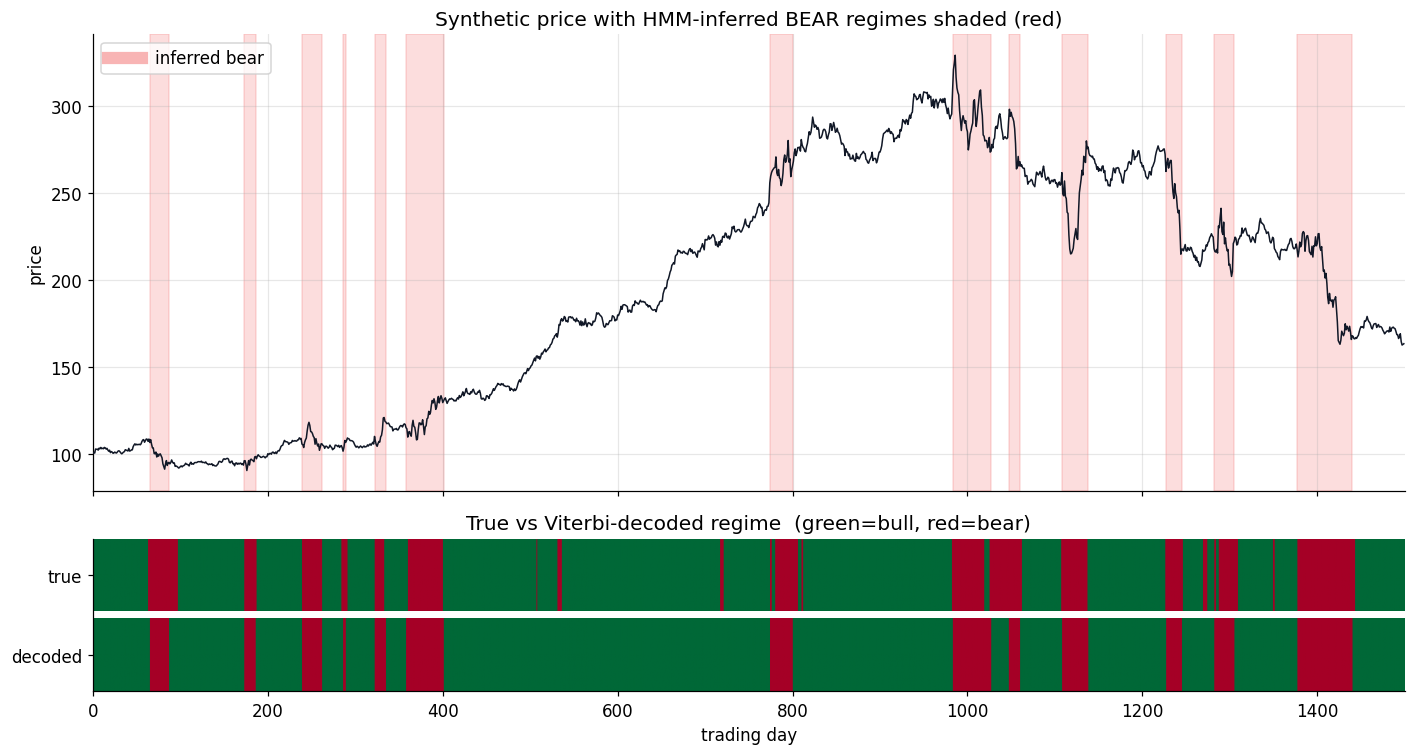

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True,
                         gridspec_kw={"height_ratios":[3,1]})

# Price shaded by INFERRED regime
ax = axes[0]
ax.plot(price, color="#111827", lw=1.0, zorder=3)
in_bear = decoded == bear
# shade contiguous bear stretches
start = None
for t in range(Tm):
    if in_bear[t] and start is None: start = t
    if (not in_bear[t] or t == Tm-1) and start is not None:
        ax.axvspan(start, t, color="#ef4444", alpha=0.18, zorder=1); start = None
ax.set(ylabel="price", title="Synthetic price with HMM-inferred BEAR regimes shaded (red)")
ax.plot([], [], color="#ef4444", alpha=0.4, lw=8, label="inferred bear"); ax.legend(loc="upper left")

# True vs decoded regime ribbons
ax2 = axes[1]
ax2.imshow(regime.reshape(1,-1), aspect="auto", cmap="RdYlGn_r", extent=[0,Tm,1.05,2.05])
shown = decoded_bear if (decoded_bear==true_bear).mean()>0.5 else 1-decoded_bear
ax2.imshow(shown.reshape(1,-1), aspect="auto", cmap="RdYlGn_r", extent=[0,Tm,-0.05,0.95])
ax2.set(yticks=[0.45,1.55], yticklabels=["decoded","true"], xlabel="trading day",
        ylim=(-0.05,2.05), title="True vs Viterbi-decoded regime  (green=bull, red=bear)")
ax2.grid(False)
plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> <i>Top:</i> a synthetic price with HMM-inferred <b>bear</b> regimes shaded red. <i>Bottom:</i> true vs Viterbi-decoded regime ribbons (green bull / red bear) &mdash; they line up ~94% of the time.<br><b>Takeaway:</b> a Gaussian HMM uncovers market regimes from returns alone &mdash; the engine behind <code>HMM&nbsp;model.ipynb</code>.
''')

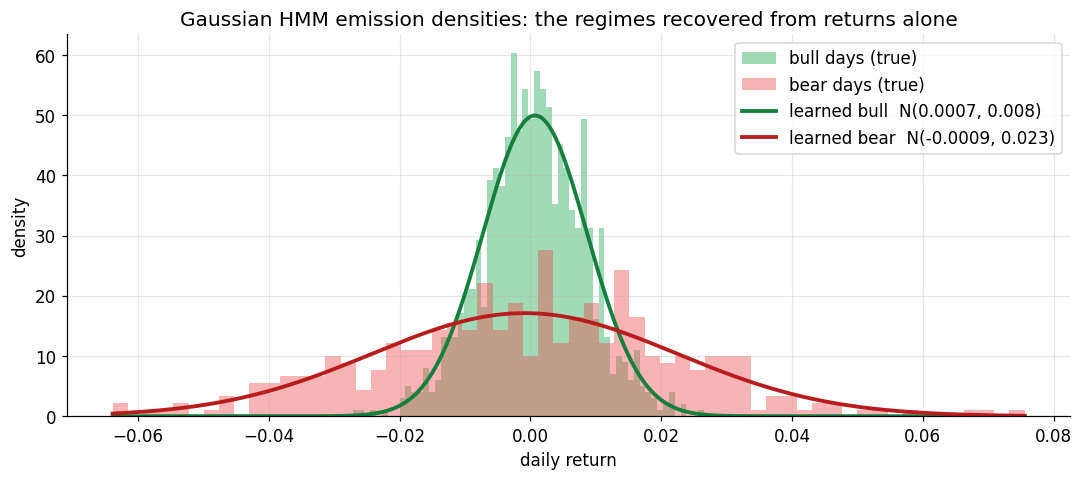

In [16]:
# Emission distributions: the two Gaussian regimes the HMM discovered
fig, ax = plt.subplots(figsize=(10, 4.5))
xs = np.linspace(returns.min(), returns.max(), 400)
ax.hist(returns[regime==0], bins=60, density=True, alpha=0.4, color="#16a34a", label="bull days (true)")
ax.hist(returns[regime==1], bins=60, density=True, alpha=0.4, color="#ef4444", label="bear days (true)")
ax.plot(xs, st.norm.pdf(xs, model.mu[bull], model.sigma[bull]), color="#15803d", lw=2.5,
        label=f"learned bull  N({model.mu[bull]:.4f}, {model.sigma[bull]:.3f})")
ax.plot(xs, st.norm.pdf(xs, model.mu[bear], model.sigma[bear]), color="#b91c1c", lw=2.5,
        label=f"learned bear  N({model.mu[bear]:.4f}, {model.sigma[bear]:.3f})")
ax.set(xlabel="daily return", ylabel="density",
       title="Gaussian HMM emission densities: the regimes recovered from returns alone")
ax.legend(); plt.tight_layout(); plt.show()

explain(r'''
<b>How to read this.</b> Histograms are the actual returns on true bull (green) vs bear (red) days; the smooth curves are the two Gaussians the HMM learned. Bear days are wider (higher volatility) and shifted slightly negative.<br><b>Takeaway:</b> each hidden state is just a Gaussian over returns &mdash; the model separates calm from turbulent days by their spread.
''')

## 11. Numerical stability, pitfalls & cheat sheet

**Stability**
- **Always** use scaling (forward/backward) or log-space (Viterbi). Naive products
  underflow to 0 within ~50–100 steps.
- Add a tiny $\varepsilon$ inside logs to avoid $\log 0$.

**Modeling pitfalls**
- **Local optima:** Baum–Welch only finds a *local* maximum. Restart from several random
  inits and keep the highest-likelihood fit.
- **Label switching:** learned states have no inherent order — state "0" may be the truth's
  state "1". Align by matching emission parameters (as we did).
- **Choosing $N$:** the number of hidden states is a modeling choice. Use BIC/AIC,
  held-out likelihood, or domain knowledge — more states always fit training data better
  (overfitting).
- **Stationarity assumption:** $A$ and $B$ are fixed over time. If the true dynamics drift,
  consider time-varying or input-driven HMMs.

**Complexity** — all three algorithms are $\mathcal{O}(N^2 T)$ time, $\mathcal{O}(NT)$
space. Linear in sequence length: HMMs scale to long sequences.

### Algorithm cheat sheet

| Goal | Algorithm | Core operation | Output |
|---|---|---|---|
| Likelihood $P(o\mid\lambda)$ | **Forward** | $\sum$ over paths (DP) | scalar likelihood |
| Most likely path | **Viterbi** | $\max$ over paths (DP) | state sequence $s^\star$ |
| Smoothed state posteriors | **Forward–Backward** | $\alpha\beta$ | $\gamma_t(i)$ |
| Learn parameters | **Baum–Welch (EM)** | E: $\gamma,\xi$; M: counts | $\hat\lambda=(\hat A,\hat B,\hat\pi)$ |

### The one idea to remember
> An HMM turns an exponential search over $N^T$ hidden paths into **linear-time dynamic
> programming**, by exploiting the Markov + output-independence factorization. *Forward
> sums, Viterbi maximizes, Baum–Welch learns.*

### References
- L. R. Rabiner, "A Tutorial on Hidden Markov Models…", *Proc. IEEE* 77(2), 1989 — the classic.
- Bishop, *Pattern Recognition and Machine Learning*, Ch. 13 (sequential data).
- Jurafsky & Martin, *Speech and Language Processing*, HMM appendix (ice-cream example).
- For production use: `hmmlearn` (Python), `pomegranate`.